# Portfolio 3: Load-Class Forecasting with Traditional ML and LSTM (Zone 1, Tetouan City)

This notebook continues Portfolio 1 (EDA) and Portfolio 2 (K-means load classes, feature engineering, DT/SVM).
The task here is **classification**: predict the Zone 1 load class (`Base Load`, `Normal Load`, `Peak Load`) **1 hour ahead**.

- **Part A** – Random Forest and MLP classifiers on tabular features.
- **Part B** – LSTM classifier on sequences of past observations.
- **Part C** – Master results table and reflection.

Kernel: conda env `aistuff` (Python 3.11, scikit-learn, TensorFlow/Keras).

In [1]:
import os, time, pickle, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, f1_score, recall_score, log_loss,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
for d in ['figures', 'models', 'results']:
    os.makedirs(d, exist_ok=True)

CLASS_NAMES = ['Base Load', 'Normal Load', 'Peak Load']
H = 6  # forecast horizon: 6 steps x 10 min = 1 hour ahead

## 1. Load and Analyse the Dataset (Step A.1)

The raw file gives the timestamp and the continuous Zone 1 load (kW). The class labels are the 3 K-means classes created in Portfolio 2
(`converted_power_consumption.csv`, same row order as the raw file). The target `zone_1_load_class` is categorical, so this is a
**classification problem**. Column cleaning and the `hour`/`month` extraction follow Portfolio 1/2.

In [2]:
raw = pd.read_csv('../data/Tetuan City power consumption.csv')
labels = pd.read_csv('../data/converted_power_consumption.csv')

# Same snake_case cleaning as Portfolio 1/2
raw.columns = (raw.columns.str.strip().str.replace(r'\s+', ' ', regex=True)
               .str.lower().str.replace(' ', '_'))
raw['datetime'] = pd.to_datetime(raw['datetime'])
raw['hour'] = raw['datetime'].dt.hour
raw['month'] = raw['datetime'].dt.month

df = raw.drop(columns=['zone_2_power_consumption', 'zone_3_power_consumption'])
df['zone_1_load_class'] = labels['zone_1_load_class'].values  # Portfolio 2 K-means labels

print('Shape:', df.shape)
print('Rows in chronological order:', df['datetime'].is_monotonic_increasing)
display(df.head())
display(df['zone_1_load_class'].value_counts().sort_index().rename(index=dict(enumerate(CLASS_NAMES))))

Shape: (52416, 10)
Rows in chronological order: True


,datetime,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,zone_1_power_consumption,hour,month,zone_1_load_class
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,0,1,1
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,0,1,1
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,0,1,1
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,0,1,0
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,0,1,0


zone_1_load_class
Base Load      18099
Normal Load    21888
Peak Load      12429
Name: count, dtype: int64

## 2. Problem Framing: Chronological Split and 1-Hour Horizon

Readings 10 minutes apart are almost identical, so a shuffled split (used in Portfolio 2) lets the model see near-copies of test rows during
training. Because an LSTM needs ordered sequences, **all models in this notebook use the same chronological 80/20 split**: the first 80% of
the year is used for training and the last 20% (mid-October to December) for testing.

The task is to predict the class **1 hour ahead** (`class[t+6]`) using information available up to time `t`. Predicting the very next
10-minute step is trivial because the class changes on only ~3.5% of steps. The naive baselines below set the bar any model has to beat.

Train period: 2017-01-01 00:00:00 -> 2017-10-19 04:30:00
Test period : 2017-10-19 04:40:00 -> 2017-12-30 23:50:00


,Overall,Train (first 80%),Test (last 20%)
Base Load,34.5,31.7,45.7
Normal Load,41.8,41.9,41.0
Peak Load,23.7,26.3,13.3


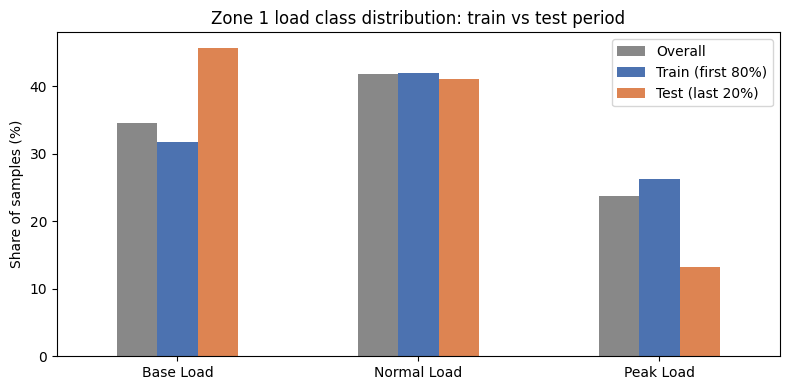

,Test accuracy
Persistence (10 min ago),0.9693
Persistence-1h (class at t),0.8283
Seasonal-24h (same time yesterday),0.8946


Share of 10-min steps where the class changes: 0.0346


In [3]:
N = len(df)
SPLIT = int(N * 0.8)  # first time index whose class belongs to the test period
y_all = df['zone_1_load_class'].values
print(f'Train period: {df.datetime[0]} -> {df.datetime[SPLIT - 1]}')
print(f'Test period : {df.datetime[SPLIT]} -> {df.datetime[N - 1]}')

dist = pd.DataFrame({
    'Overall': np.bincount(y_all) / N * 100,
    'Train (first 80%)': np.bincount(y_all[:SPLIT]) / SPLIT * 100,
    'Test (last 20%)': np.bincount(y_all[SPLIT:]) / (N - SPLIT) * 100,
}, index=CLASS_NAMES)
display(dist.round(1))

ax = dist.plot(kind='bar', figsize=(8, 4), rot=0, color=['#888888', '#4C72B0', '#DD8452'])
ax.set_ylabel('Share of samples (%)')
ax.set_title('Zone 1 load class distribution: train vs test period')
plt.tight_layout()
plt.savefig('figures/p3_class_shift.png', dpi=150)
plt.show()

# Naive baselines on the test targets class[t+H]
test_t = np.arange(SPLIT - H, N - H)  # anchor times whose target falls in the test period
y_test_ref = y_all[test_t + H]
baselines = {
    'Persistence (10 min ago)': y_all[test_t + H - 1],
    'Persistence-1h (class at t)': y_all[test_t],
    'Seasonal-24h (same time yesterday)': y_all[test_t + H - 144],
}
display(pd.DataFrame({'Test accuracy': {k: accuracy_score(y_test_ref, v) for k, v in baselines.items()}}).round(4))
print('Share of 10-min steps where the class changes:', round((y_all[1:] != y_all[:-1]).mean(), 4))